1. Configuración e importación de librerías

In [1]:
import os, json, platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Librerías de los Modelos de Ensamble
import sklearn, xgboost, lightgbm, shap
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor, early_stopping
from IPython.display import display

# Métricas de Evaluación
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Motor de Explicabilidad Post-Hoc (XAI)
import warnings
warnings.filterwarnings('ignore')

SEMILLA = 42
np.random.seed(SEMILLA)

OBJETIVOS = {'PM2.5': 'pm2_5', 'PM10': 'pm10'}

# Versiones (necesarias para reproducir los resultados y cargar los modelos en Django)
VERSIONES = {'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__,
             'scikit-learn': sklearn.__version__, 'xgboost': xgboost.__version__,
             'lightgbm': lightgbm.__version__, 'shap': shap.__version__}
print(VERSIONES)

{'python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6', 'scikit-learn': '1.6.1', 'xgboost': '3.4.1', 'lightgbm': '4.6.0', 'shap': '0.54.1'}


2. Carga del dataset y Poda controlada de borde (1.296 registros)

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Cargamos el archivo original desde Google Drive
df = pd.read_csv("/content/drive/MyDrive/air_quality_historical.csv")
def depurar_datos(df):
    df = df.copy()
    df['date'] = pd.to_datetime(df['date'])
    df = df.sort_values('date').reset_index(drop=True)
    # 1. Poda de borde: 2022-08-01 y 2022-08-02 sin ningún dato
    df = df.iloc[2:].reset_index(drop=True)
    # 2. AQI nulos del 2022-08-03 -> valor del día siguiente (no se usan como predictores)
    df[['us_aqi', 'european_aqi']] = df[['us_aqi', 'european_aqi']].bfill()
    # 3. NO2 = 0 (2022-12-14, dato inválido) -> interpolación lineal
    df.loc[df['nitrogen_dioxide'] == 0, 'nitrogen_dioxide'] = np.nan
    df['nitrogen_dioxide'] = df['nitrogen_dioxide'].interpolate(method='linear')
    # 4. UV = 0 (2022-08-03, registro incompleto) -> valor del día siguiente
    df.loc[df['uv_index'] == 0, 'uv_index'] = np.nan
    df['uv_index'] = df['uv_index'].bfill()
    return df

df_cleaned = depurar_datos(df)
print('Dimensiones tras la depuración:', df_cleaned.shape)
print('Rango:', df_cleaned['date'].min().date(), 'a', df_cleaned['date'].max().date())
print('Valores nulos:', int(df_cleaned.isnull().sum().sum()))

meteo_d = pd.read_csv('/content/drive/MyDrive/meteorologia_diaria.csv', parse_dates=['date'])
COLS_METEO = [c for c in meteo_d.columns if c != 'date']
df_cleaned = df_cleaned.merge(meteo_d, on='date', how='left')
df_cleaned[COLS_METEO] = df_cleaned[COLS_METEO].interpolate(method='linear').bfill().ffill()
print('Variables meteorológicas integradas:', len(COLS_METEO))

Dimensiones tras la depuración: (1296, 12)
Rango: 2022-08-03 a 2026-02-18
Valores nulos: 0
Variables meteorológicas integradas: 15


3. Ingeniería de Variables Temporales

In [4]:
CONTAMINANTES = ['pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide', 'ozone']
OPTICAS = ['aerosol_optical_depth', 'dust', 'uv_index']

df_model = df_cleaned.copy()
for col in CONTAMINANTES:
    df_model[f'{col}_lag1'] = df_model[col].shift(1)
    df_model[f'{col}_lag2'] = df_model[col].shift(2)
for col in OPTICAS:
    df_model[f'{col}_lag1'] = df_model[col].shift(1)
for obj in ['pm10', 'pm2_5']:
    # min_periods=2: en la primera fila útil solo existen t-1 y t-2 (se promedian esos dos días)
    df_model[f'{obj}_ma3'] = df_model[obj].shift(1).rolling(window=3, min_periods=2).mean()
    df_model[f'{obj}_delta'] = df_model[obj].shift(1) - df_model[obj].shift(2)
df_model['mes'] = df_model['date'].dt.month
df_model['dia_semana'] = df_model['date'].dt.dayofweek          # 0 = lunes ... 6 = domingo

for col in COLS_METEO:
    df_model[f'{col}_lag1'] = df_model[col].shift(1)     # meteorología del día anterior

# Se descartan los 2 primeros días, que no tienen dos días previos de historia
df_model = df_model.iloc[2:].reset_index(drop=True)
assert df_model.isnull().sum().sum() == 0
print('Matriz de modelado:', df_model.shape, '|', df_model['date'].min().date(), 'a', df_model['date'].max().date())

Matriz de modelado: (1294, 63) | 2022-08-05 a 2026-02-18


In [5]:
# Conjuntos de variables de cada escenario
REZAGOS = [f'{c}_{s}' for c in CONTAMINANTES for s in ['lag1', 'lag2']] + \
          ['pm10_ma3', 'pm10_delta', 'pm2_5_ma3', 'pm2_5_delta']
FEATURES_A = REZAGOS + [f'{c}_lag1' for c in OPTICAS] + ['mes', 'dia_semana']           # Pronóstico 24 h
FEATURES_B = ['carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide', 'ozone'] + OPTICAS + REZAGOS  # Mismo día

FEATURES_C = FEATURES_A + COLS_METEO + [f'{c}_lag1' for c in COLS_METEO]   # + meteorología de t (pronóstico) y t−1

ESCENARIOS = {'A. Pronóstico 24 h': FEATURES_A,
              'B. Estimación mismo día': FEATURES_B,
              'C. Pronóstico 24 h + meteorología': FEATURES_C}
for nombre, feats in ESCENARIOS.items():
    print(f'{nombre}: {len(feats)} variables')

concurrentes = set(CONTAMINANTES + OPTICAS + ['us_aqi', 'european_aqi'])
assert not set(FEATURES_A) & concurrentes, 'Fuga de información en el escenario A'
assert not set(FEATURES_C) & concurrentes, 'Fuga de información en el escenario C'
assert not set(FEATURES_B) & {'pm10', 'pm2_5', 'us_aqi', 'european_aqi'}, 'Fuga del objetivo en el escenario B'
print('Control anti-fuga superado. La meteorología del día t se trata como pronóstico meteorológico disponible.')

A. Pronóstico 24 h: 21 variables
B. Estimación mismo día: 23 variables
C. Pronóstico 24 h + meteorología: 51 variables
Control anti-fuga superado. La meteorología del día t se trata como pronóstico meteorológico disponible.


4. Partición Cronológica Hermética (70% Entrenamiento, 15% Validación, 15% Prueba)

In [6]:
n = len(df_model)
n_test = n_val = round(n * 0.15)
n_train = n - n_val - n_test                                 # 906 | 194 | 194

train_df = df_model.iloc[:n_train].copy()
val_df   = df_model.iloc[n_train:n_train + n_val].copy()
test_df  = df_model.iloc[n_train + n_val:].copy()

for nombre, d in [('Entrenamiento 70%', train_df), ('Validación 15%', val_df), ('Prueba 15%', test_df)]:
    print(f"{nombre:18s}: {len(d):4d} días | {d['date'].min().date()} a {d['date'].max().date()}")

Entrenamiento 70% :  906 días | 2022-08-05 a 2025-01-26
Validación 15%    :  194 días | 2025-01-27 a 2025-08-08
Prueba 15%        :  194 días | 2025-08-09 a 2026-02-18


In [7]:
# Caracterización de cada partición: ¿contienen episodios críticos?
# Umbral de "día crítico": percentil 90 del conjunto de ENTRENAMIENTO (no se usa información futura)
UMBRAL_P90 = {obj: train_df[col].quantile(0.90) for obj, col in OBJETIVOS.items()}
filas = []
for nombre, d in [('Entrenamiento', train_df), ('Validación', val_df), ('Prueba', test_df)]:
    fila = {'Partición': nombre}
    for obj, col in OBJETIVOS.items():
        fila[f'{obj} media'] = d[col].mean()
        fila[f'{obj} desv.'] = d[col].std()
        fila[f'{obj} máx.'] = d[col].max()
        fila[f'{obj} días > P90'] = int((d[col] > UMBRAL_P90[obj]).sum())
    filas.append(fila)
print('Umbral P90 de entrenamiento (µg/m³):', {k: round(v, 2) for k, v in UMBRAL_P90.items()})
display(pd.DataFrame(filas).set_index('Partición'))

Umbral P90 de entrenamiento (µg/m³): {'PM2.5': np.float64(18.35), 'PM10': np.float64(25.56)}


,PM2.5 media,PM2.5 desv.,PM2.5 máx.,PM2.5 días > P90,PM10 media,PM10 desv.,PM10 máx.,PM10 días > P90
Partición,,,,,,,,
Entrenamiento,13.259359,4.033137,31.325000,91,18.391492,5.679722,44.804167,91
Validación,14.903243,4.260857,32.741667,33,15.225859,4.426120,33.087500,6
Prueba,14.160009,3.923830,25.654167,27,14.452878,4.106496,27.333333,2


5. Modelos de referencia (baselines)

In [8]:
def metricas(y_real, y_pred, umbral):
    y_real, y_pred = np.asarray(y_real), np.asarray(y_pred)
    pico = y_real > umbral
    return {
        'MAE': mean_absolute_error(y_real, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_real, y_pred)),
        'R²': r2_score(y_real, y_pred),
        'MAE picos': mean_absolute_error(y_real[pico], y_pred[pico]) if pico.any() else np.nan,
        'Sesgo picos': np.mean(y_pred[pico] - y_real[pico]) if pico.any() else np.nan,
        'n picos': int(pico.sum()),
    }

resultados = []
for obj, col in OBJETIVOS.items():
    for part, d in [('Validación', val_df), ('Prueba', test_df)]:
        referencias = {
            'Persistencia (t−1)': d[f'{col}_lag1'],
            'Media móvil 3 días': d[f'{col}_ma3'],
            'Media histórica': np.full(len(d), train_df[col].mean()),
        }
        for nombre, pred in referencias.items():
            resultados.append({'Contaminante': obj, 'Escenario': 'Referencia', 'Modelo': nombre,
                               'Partición': part, **metricas(d[col], pred, UMBRAL_P90[obj])})
tabla_referencias = pd.DataFrame(resultados)
display(tabla_referencias)

,Contaminante,Escenario,Modelo,Partición,MAE,RMSE,R²,MAE picos,Sesgo picos,n picos
0,PM2.5,Referencia,Persistencia (t−1),Validación,3.285202,4.220135,0.013940,5.123990,-3.497222,33
1,PM2.5,Referencia,Media móvil 3 días,Validación,3.273046,4.334888,-0.040414,5.822559,-4.115909,33
2,PM2.5,Referencia,Media histórica,Validación,3.410142,4.556717,-0.149621,8.381803,-8.381803,33
3,PM2.5,Referencia,Persistencia (t−1),Prueba,3.125150,3.919117,-0.002768,3.524074,-2.596296,27
4,PM2.5,Referencia,Media móvil 3 días,Prueba,3.299105,4.115643,-0.105858,4.542798,-4.340432,27
5,PM2.5,Referencia,Media histórica,Prueba,3.254878,4.015999,-0.052959,7.148820,-7.148820,27
6,PM10,Referencia,Persistencia (t−1),Validación,3.362156,4.342662,0.032368,6.752778,-5.612500,6
7,PM10,Referencia,Media móvil 3 días,Validación,3.385145,4.478542,-0.029133,11.040741,-11.040741,6
8,PM10,Referencia,Media histórica,Validación,4.481804,5.432384,-0.514185,10.957814,-10.957814,6
9,PM10,Referencia,Persistencia (t−1),Prueba,3.241903,4.114005,-0.008861,10.470833,-10.470833,2


6. Entrenamiento de los modelos de ensamble

In [9]:
resultados = [r for r in resultados if r['Escenario'] == 'Referencia']   # evita duplicados al re-ejecutar

PARAMS = {
    'XGBoost': dict(learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                    reg_alpha=0.1, reg_lambda=1.0, random_state=SEMILLA),
    'LightGBM': dict(learning_rate=0.03, max_depth=4, num_leaves=15, subsample=0.8, subsample_freq=1,
                     colsample_bytree=0.8, reg_alpha=0.1, reg_lambda=1.0, random_state=SEMILLA, verbose=-1),
    'Random Forest': dict(n_estimators=300, max_depth=8, min_samples_split=5, min_samples_leaf=2,
                          random_state=SEMILLA, n_jobs=-1),
}
MAX_ARBOLES, PACIENCIA = 1000, 50

def entrenar(nombre, X_tr, y_tr, X_va, y_va):
    # Devuelve el modelo final y el número de árboles usado
    if nombre == 'XGBoost':
        sonda = XGBRegressor(n_estimators=MAX_ARBOLES, early_stopping_rounds=PACIENCIA,
                             eval_metric='mae', **PARAMS[nombre])
        sonda.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
        n_arboles = sonda.best_iteration + 1
        modelo = XGBRegressor(n_estimators=n_arboles, **PARAMS[nombre]).fit(X_tr, y_tr)
    elif nombre == 'LightGBM':
        sonda = LGBMRegressor(n_estimators=MAX_ARBOLES, **PARAMS[nombre])
        sonda.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], eval_metric='l1',
                  callbacks=[early_stopping(PACIENCIA, verbose=False)])
        n_arboles = sonda.best_iteration_
        modelo = LGBMRegressor(n_estimators=n_arboles, **PARAMS[nombre]).fit(X_tr, y_tr)
    else:
        modelo = RandomForestRegressor(**PARAMS[nombre]).fit(X_tr, y_tr)
        n_arboles = PARAMS[nombre]['n_estimators']
    return modelo, n_arboles

modelos, predicciones, arboles = {}, {}, []
for esc, feats in ESCENARIOS.items():
    for obj, col in OBJETIVOS.items():
        for nombre in PARAMS:
            modelo, n_arb = entrenar(nombre, train_df[feats], train_df[col], val_df[feats], val_df[col])
            modelos[(esc, obj, nombre)] = modelo
            arboles.append({'Escenario': esc, 'Contaminante': obj, 'Modelo': nombre, 'Árboles': n_arb})
            for part, d in [('Validación', val_df), ('Prueba', test_df)]:
                pred = modelo.predict(d[feats])
                predicciones[(esc, obj, nombre, part)] = pred
                resultados.append({'Contaminante': obj, 'Escenario': esc, 'Modelo': nombre, 'Partición': part,
                                   **metricas(d[col], pred, UMBRAL_P90[obj])})
print('Entrenamiento completado.')
print('\n--- NÚMERO DE ÁRBOLES (definido por parada temprana en XGBoost y LightGBM) ---')
display(pd.DataFrame(arboles).pivot_table(index=['Escenario', 'Modelo'], columns='Contaminante', values='Árboles'))

Entrenamiento completado.

--- NÚMERO DE ÁRBOLES (definido por parada temprana en XGBoost y LightGBM) ---


Contaminante                                      PM10  PM2.5
Escenario                         Modelo                     
A. Pronóstico 24 h                LightGBM       233.0  131.0
                                  Random Forest  300.0  300.0
                                  XGBoost        105.0  190.0
B. Estimación mismo día           LightGBM       462.0  244.0
                                  Random Forest  300.0  300.0
                                  XGBoost        528.0  371.0
C. Pronóstico 24 h + meteorología LightGBM       375.0  382.0
                                  Random Forest  300.0  300.0
                                  XGBoost        346.0  472.0

In [10]:
# Tabla de hiperparámetros
filas = []
for nombre, p in PARAMS.items():
    for k, v in p.items():
        if k not in ('random_state', 'verbose', 'n_jobs'):
            filas.append({'Modelo': nombre, 'Hiperparámetro': k, 'Valor': v})
filas += [{'Modelo': m, 'Hiperparámetro': 'n_estimators', 'Valor': f'parada temprana (máx. {MAX_ARBOLES}, paciencia {PACIENCIA})'}
          for m in ['XGBoost', 'LightGBM']]
display(pd.DataFrame(filas))

,Modelo,Hiperparámetro,Valor
0,XGBoost,learning_rate,0.03
1,XGBoost,max_depth,4
2,XGBoost,subsample,0.8
3,XGBoost,colsample_bytree,0.8
4,XGBoost,reg_alpha,0.1
5,XGBoost,reg_lambda,1.0
6,LightGBM,learning_rate,0.03
7,LightGBM,max_depth,4
8,LightGBM,num_leaves,15
9,LightGBM,subsample,0.8


7. Evaluación Comparativa del Desempeño Predictivo (Validación y Prueba)

In [11]:
tabla_resultados = pd.DataFrame(resultados)
COLS_MOSTRAR = ['Escenario', 'Modelo', 'MAE', 'RMSE', 'R²', 'MAE picos', 'Sesgo picos']
for obj in OBJETIVOS:
    for part in ['Validación', 'Prueba']:
        t = tabla_resultados[(tabla_resultados['Contaminante'] == obj) & (tabla_resultados['Partición'] == part)]
        print(f'\n=== {obj} — {part} (n picos = {t["n picos"].iloc[0]}) ===')
        display(t[COLS_MOSTRAR].reset_index(drop=True))


=== PM2.5 — Validación (n picos = 33) ===


,Escenario,Modelo,MAE,RMSE,R²,MAE picos,Sesgo picos
0,Referencia,Persistencia (t−1),3.285202,4.220135,0.013940,5.123990,-3.497222
1,Referencia,Media móvil 3 días,3.273046,4.334888,-0.040414,5.822559,-4.115909
2,Referencia,Media histórica,3.410142,4.556717,-0.149621,8.381803,-8.381803
3,A. Pronóstico 24 h,XGBoost,2.741037,3.650883,0.262017,5.100940,-4.972699
4,A. Pronóstico 24 h,LightGBM,2.776609,3.711406,0.237346,5.379135,-5.210867
5,A. Pronóstico 24 h,Random Forest,2.797018,3.724919,0.231783,5.488263,-5.417934
6,B. Estimación mismo día,XGBoost,1.844893,2.493552,0.655739,3.256028,-2.942353
7,B. Estimación mismo día,LightGBM,1.844449,2.480684,0.659283,3.399911,-3.005876
8,B. Estimación mismo día,Random Forest,2.032763,2.811098,0.562475,3.849629,-3.776132
9,C. Pronóstico 24 h + meteorología,XGBoost,2.662649,3.564879,0.296377,5.335103,-5.210839



=== PM2.5 — Prueba (n picos = 27) ===


,Escenario,Modelo,MAE,RMSE,R²,MAE picos,Sesgo picos
0,Referencia,Persistencia (t−1),3.125150,3.919117,-0.002768,3.524074,-2.596296
1,Referencia,Media móvil 3 días,3.299105,4.115643,-0.105858,4.542798,-4.340432
2,Referencia,Media histórica,3.254878,4.015999,-0.052959,7.148820,-7.148820
3,A. Pronóstico 24 h,XGBoost,2.432290,3.181416,0.339208,3.852069,-3.671135
4,A. Pronóstico 24 h,LightGBM,2.502591,3.262296,0.305182,3.866269,-3.849354
5,A. Pronóstico 24 h,Random Forest,2.592705,3.342057,0.270792,4.002826,-4.002826
6,B. Estimación mismo día,XGBoost,1.746865,2.158523,0.695815,2.165876,-1.886384
7,B. Estimación mismo día,LightGBM,1.798408,2.174594,0.691269,2.169778,-1.905201
8,B. Estimación mismo día,Random Forest,1.870309,2.331290,0.645173,2.534992,-2.449362
9,C. Pronóstico 24 h + meteorología,XGBoost,2.395224,3.065673,0.386414,3.691322,-3.472570



=== PM10 — Validación (n picos = 6) ===


,Escenario,Modelo,MAE,RMSE,R²,MAE picos,Sesgo picos
0,Referencia,Persistencia (t−1),3.362156,4.342662,0.032368,6.752778,-5.612500
1,Referencia,Media móvil 3 días,3.385145,4.478542,-0.029133,11.040741,-11.040741
2,Referencia,Media histórica,4.481804,5.432384,-0.514185,10.957814,-10.957814
3,A. Pronóstico 24 h,XGBoost,2.968693,3.803436,0.257750,8.571055,-8.571055
4,A. Pronóstico 24 h,LightGBM,2.980951,3.830975,0.246963,8.203763,-8.203763
5,A. Pronóstico 24 h,Random Forest,3.024519,3.884964,0.225588,7.642612,-7.642612
6,B. Estimación mismo día,XGBoost,2.184241,2.666755,0.635108,4.185628,-4.063839
7,B. Estimación mismo día,LightGBM,2.170086,2.700984,0.625681,3.808654,-2.910744
8,B. Estimación mismo día,Random Forest,2.691268,3.253630,0.456832,4.084847,-4.084847
9,C. Pronóstico 24 h + meteorología,XGBoost,2.794010,3.592002,0.337980,6.848754,-6.848754



=== PM10 — Prueba (n picos = 2) ===


,Escenario,Modelo,MAE,RMSE,R²,MAE picos,Sesgo picos
0,Referencia,Persistencia (t−1),3.241903,4.114005,-0.008861,10.470833,-10.470833
1,Referencia,Media móvil 3 días,3.456522,4.359911,-0.133071,12.407639,-12.407639
2,Referencia,Media histórica,4.717452,5.682346,-0.924674,8.287675,-8.287675
3,A. Pronóstico 24 h,XGBoost,2.557593,3.298207,0.351578,9.382606,-9.382606
4,A. Pronóstico 24 h,LightGBM,2.471681,3.186344,0.394816,9.392493,-9.392493
5,A. Pronóstico 24 h,Random Forest,2.701452,3.453352,0.289141,8.911035,-8.911035
6,B. Estimación mismo día,XGBoost,1.741792,2.258557,0.695937,6.108739,-6.108739
7,B. Estimación mismo día,LightGBM,1.709159,2.251006,0.697966,5.200152,-5.200152
8,B. Estimación mismo día,Random Forest,2.098272,2.672798,0.574172,7.304606,-7.304606
9,C. Pronóstico 24 h + meteorología,XGBoost,2.502266,3.237612,0.375185,8.828308,-8.828308


8. Selección del modelo por contaminante y escenario

In [12]:
val = tabla_resultados[(tabla_resultados['Partición'] == 'Validación') & (tabla_resultados['Escenario'] != 'Referencia')].copy()
grupo = val.groupby(['Escenario', 'Contaminante'])
val['Rank MAE'] = grupo['MAE'].rank(method='min')
val['Rank RMSE'] = grupo['RMSE'].rank(method='min')
val['Rank R²'] = grupo['R²'].rank(method='min', ascending=False)
val['Puntaje'] = val[['Rank MAE', 'Rank RMSE', 'Rank R²']].sum(axis=1)
val = val.sort_values(['Escenario', 'Contaminante', 'Puntaje', 'MAE'])
val['Decisión'] = np.where(val.groupby(['Escenario', 'Contaminante']).cumcount() == 0, 'SELECCIONADO', 'Descartado')

print('--- MATRIZ DE SELECCIÓN (conjunto de VALIDACIÓN) ---')
display(val[['Escenario', 'Contaminante', 'Modelo', 'MAE', 'RMSE', 'R²', 'Rank MAE', 'Rank RMSE', 'Rank R²', 'Puntaje', 'Decisión']]
        .reset_index(drop=True))

MEJOR = {(r['Escenario'], r['Contaminante']): r['Modelo'] for _, r in val[val['Decisión'] == 'SELECCIONADO'].iterrows()}
print('Modelos seleccionados:')
for k, v in MEJOR.items():
    print(f'  {k[0]} | {k[1]} -> {v}')

--- MATRIZ DE SELECCIÓN (conjunto de VALIDACIÓN) ---


,Escenario,Contaminante,Modelo,MAE,RMSE,R²,Rank MAE,Rank RMSE,Rank R²,Puntaje,Decisión
0,A. Pronóstico 24 h,PM10,XGBoost,2.968693,3.803436,0.257750,1.0,1.0,1.0,3.0,SELECCIONADO
1,A. Pronóstico 24 h,PM10,LightGBM,2.980951,3.830975,0.246963,2.0,2.0,2.0,6.0,Descartado
2,A. Pronóstico 24 h,PM10,Random Forest,3.024519,3.884964,0.225588,3.0,3.0,3.0,9.0,Descartado
3,A. Pronóstico 24 h,PM2.5,XGBoost,2.741037,3.650883,0.262017,1.0,1.0,1.0,3.0,SELECCIONADO
4,A. Pronóstico 24 h,PM2.5,LightGBM,2.776609,3.711406,0.237346,2.0,2.0,2.0,6.0,Descartado
5,A. Pronóstico 24 h,PM2.5,Random Forest,2.797018,3.724919,0.231783,3.0,3.0,3.0,9.0,Descartado
6,B. Estimación mismo día,PM10,XGBoost,2.184241,2.666755,0.635108,2.0,1.0,1.0,4.0,SELECCIONADO
7,B. Estimación mismo día,PM10,LightGBM,2.170086,2.700984,0.625681,1.0,2.0,2.0,5.0,Descartado
8,B. Estimación mismo día,PM10,Random Forest,2.691268,3.253630,0.456832,3.0,3.0,3.0,9.0,Descartado
9,B. Estimación mismo día,PM2.5,LightGBM,1.844449,2.480684,0.659283,1.0,1.0,1.0,3.0,SELECCIONADO


Modelos seleccionados:
  A. Pronóstico 24 h | PM10 -> XGBoost
  A. Pronóstico 24 h | PM2.5 -> XGBoost
  B. Estimación mismo día | PM10 -> XGBoost
  B. Estimación mismo día | PM2.5 -> LightGBM
  C. Pronóstico 24 h + meteorología | PM10 -> LightGBM
  C. Pronóstico 24 h + meteorología | PM2.5 -> LightGBM


In [13]:
# Tabla resumen final: modelos seleccionados vs. referencias, en el conjunto de PRUEBA
filas = []
for obj, col in OBJETIVOS.items():
    t = tabla_resultados[(tabla_resultados['Contaminante'] == obj) & (tabla_resultados['Partición'] == 'Prueba')]
    persist = t[t['Modelo'] == 'Persistencia (t−1)'].iloc[0]
    filas.append({'Contaminante': obj, 'Modelo': 'Persistencia (t−1)', **persist[['MAE', 'RMSE', 'R²', 'MAE picos']].to_dict()})
    for esc in ESCENARIOS:
        r = t[(t['Escenario'] == esc) & (t['Modelo'] == MEJOR[(esc, obj)])].iloc[0]
        filas.append({'Contaminante': obj, 'Modelo': f'{esc} ({MEJOR[(esc, obj)]})',
                      **r[['MAE', 'RMSE', 'R²', 'MAE picos']].to_dict(),
                      'Mejora MAE vs persistencia (%)': (1 - r['MAE'] / persist['MAE']) * 100})
resumen_prueba = pd.DataFrame(filas)
print('--- RESULTADO FINAL EN PRUEBA ---')
display(resumen_prueba)

--- RESULTADO FINAL EN PRUEBA ---


,Contaminante,Modelo,MAE,RMSE,R²,MAE picos,Mejora MAE vs persistencia (%)
0,PM2.5,Persistencia (t−1),3.125150,3.919117,-0.002768,3.524074,NaN
1,PM2.5,A. Pronóstico 24 h (XGBoost),2.432290,3.181416,0.339208,3.852069,22.170450
2,PM2.5,B. Estimación mismo día (LightGBM),1.798408,2.174594,0.691269,2.169778,42.453709
3,PM2.5,C. Pronóstico 24 h + meteorología (LightGBM),2.404474,3.099120,0.372952,3.628922,23.060526
4,PM10,Persistencia (t−1),3.241903,4.114005,-0.008861,10.470833,NaN
5,PM10,A. Pronóstico 24 h (XGBoost),2.557593,3.298207,0.351578,9.382606,21.108279
6,PM10,B. Estimación mismo día (XGBoost),1.741792,2.258557,0.695937,6.108739,46.272535
7,PM10,C. Pronóstico 24 h + meteorología (LightGBM),2.485559,3.190050,0.393408,8.895598,23.330238


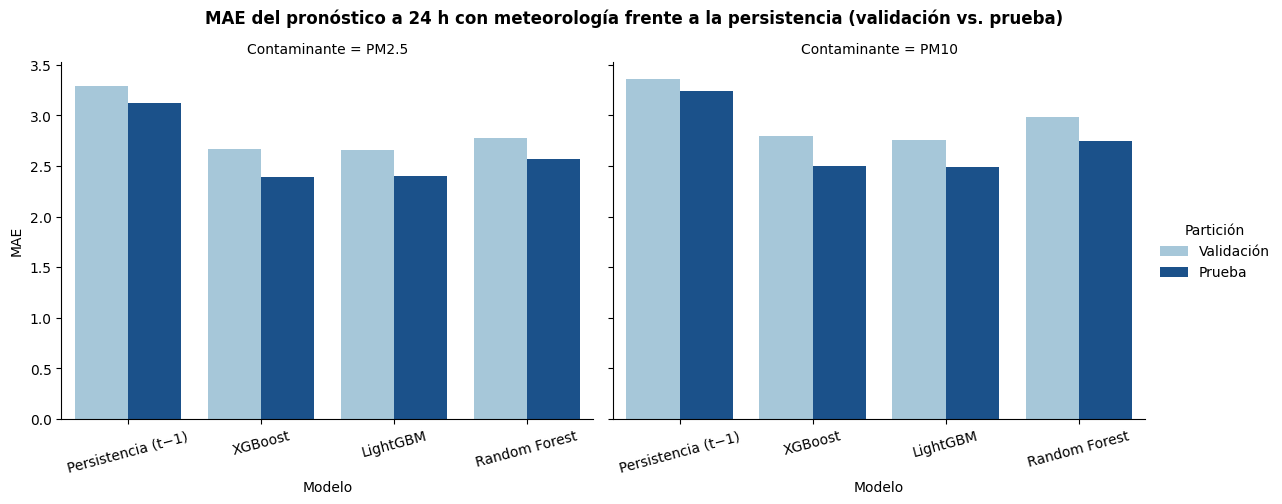

In [14]:
# Gráfico: MAE de cada modelo en validación y prueba (escenario principal) frente a la persistencia
esc_a = 'C. Pronóstico 24 h + meteorología'    # escenario principal (mejor en validación que A)
FEATURES_P = ESCENARIOS[esc_a]                   # variables del escenario principal (51)
t = tabla_resultados[tabla_resultados['Escenario'].isin([esc_a, 'Referencia']) &
                     tabla_resultados['Modelo'].isin(list(PARAMS) + ['Persistencia (t−1)'])]
g = sns.catplot(data=t, x='Modelo', y='MAE', hue='Partición', col='Contaminante', kind='bar',
                palette=['#9ecae1', '#08519c'], height=4.5, aspect=1.3)
g.set_xticklabels(rotation=15)
g.fig.suptitle('MAE del pronóstico a 24 h con meteorología frente a la persistencia (validación vs. prueba)',
               y=1.04, fontweight='bold')
plt.show()

9. Seguimiento temporal en el conjunto de prueba

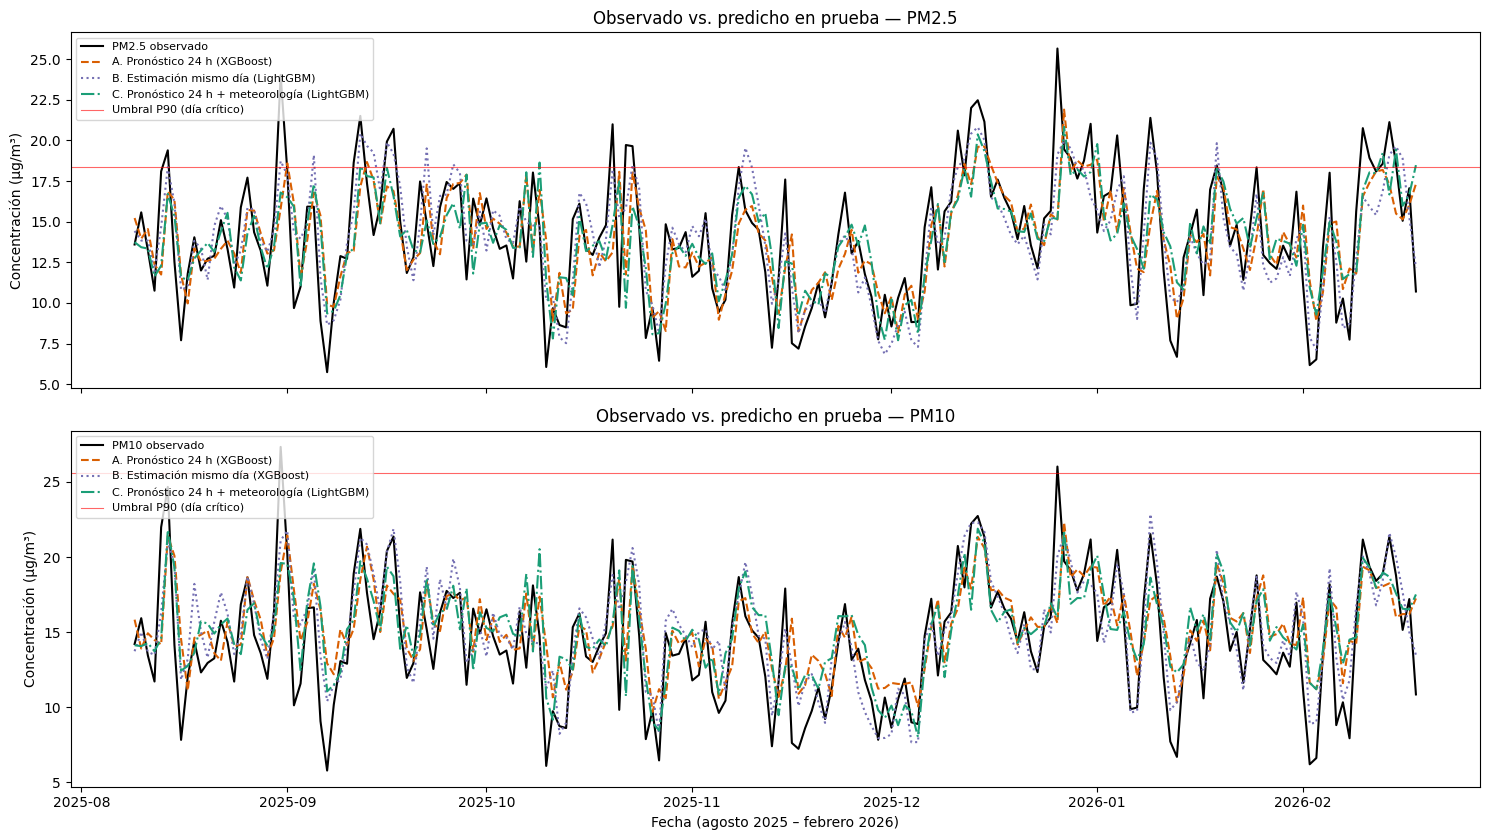

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(15, 8.5), sharex=True)
for ax, (obj, col) in zip(axes, OBJETIVOS.items()):
    ax.plot(test_df['date'], test_df[col], color='black', linewidth=1.5, label=f'{obj} observado')
    for esc, color, estilo in [('A. Pronóstico 24 h', '#d95f02', '--'), ('B. Estimación mismo día', '#7570b3', ':'),
                               ('C. Pronóstico 24 h + meteorología', '#1b9e77', '-.')]:
        mod = MEJOR[(esc, obj)]
        ax.plot(test_df['date'], predicciones[(esc, obj, mod, 'Prueba')], color=color, linestyle=estilo,
                linewidth=1.5, label=f'{esc} ({mod})')
    ax.axhline(UMBRAL_P90[obj], color='red', linewidth=0.8, alpha=0.6, label='Umbral P90 (día crítico)')
    ax.set_ylabel('Concentración (µg/m³)')
    ax.set_title(f'Observado vs. predicho en prueba — {obj}')
    ax.legend(loc='upper left', fontsize=8)
axes[1].set_xlabel('Fecha (agosto 2025 – febrero 2026)')
plt.tight_layout()
plt.show()

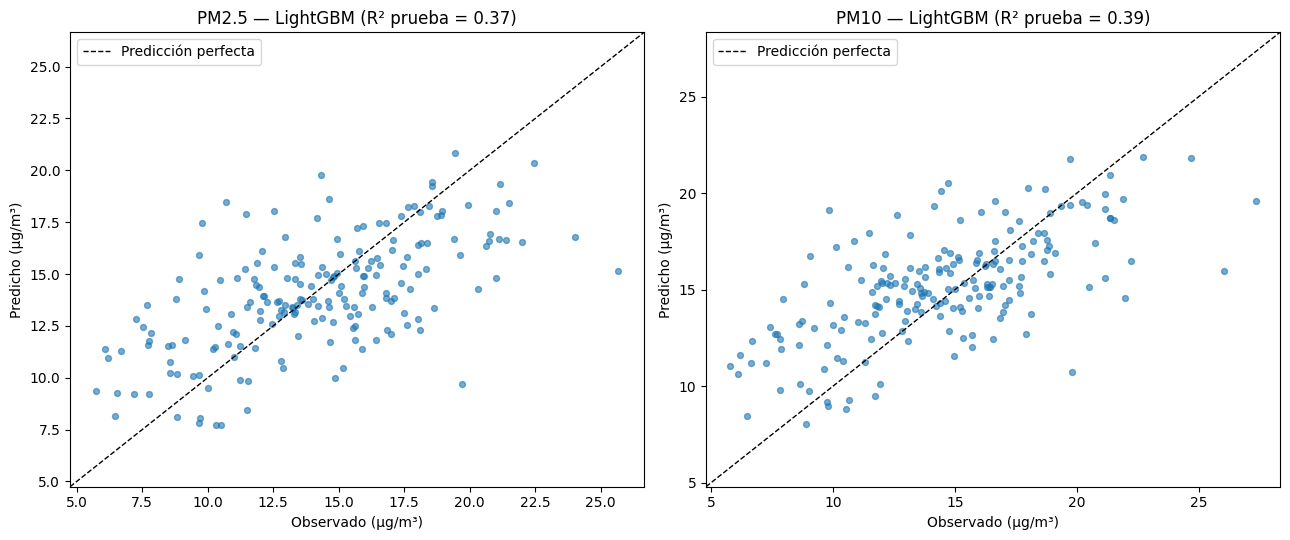

In [17]:
# Dispersión observado vs. predicho del modelo principal
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (obj, col) in zip(axes, OBJETIVOS.items()):
    mod = MEJOR[(esc_a, obj)]
    pred = predicciones[(esc_a, obj, mod, 'Prueba')]
    r2 = r2_score(test_df[col], pred)
    ax.scatter(test_df[col], pred, alpha=0.6, s=18)
    lim = [min(test_df[col].min(), pred.min()) - 1, max(test_df[col].max(), pred.max()) + 1]
    ax.plot(lim, lim, 'k--', linewidth=1, label='Predicción perfecta')
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel('Observado (µg/m³)'); ax.set_ylabel('Predicho (µg/m³)')
    ax.set_title(f'{obj} — {mod} (R² prueba = {r2:.2f})')
    ax.legend()
plt.tight_layout()
plt.show()

10.  Explicabilidad con TreeSHAP (modelo principal: pronóstico a 24 h)



 TreeSHAP — PM2.5 — C. Pronóstico 24 h + meteorología (modelo seleccionado: LightGBM)


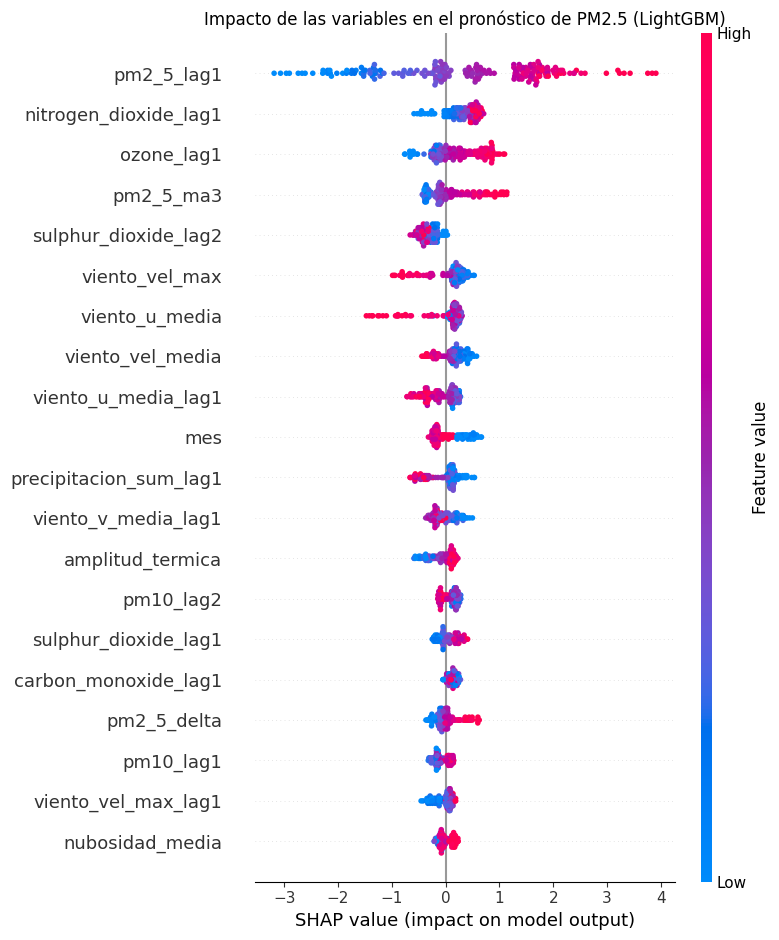

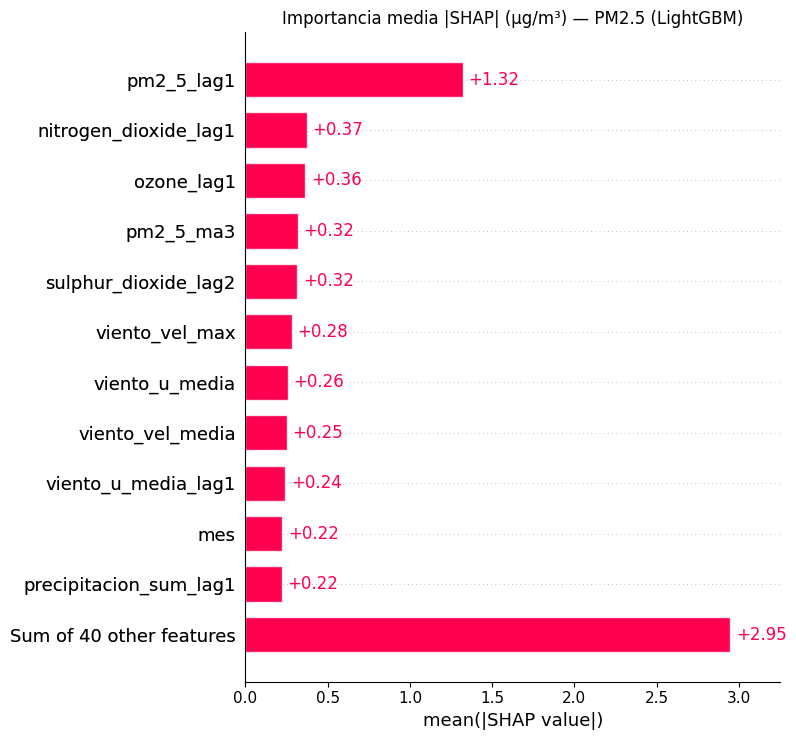

Día de mayor PM2.5 en prueba: 2025-12-26 (observado = 25.65 µg/m³)


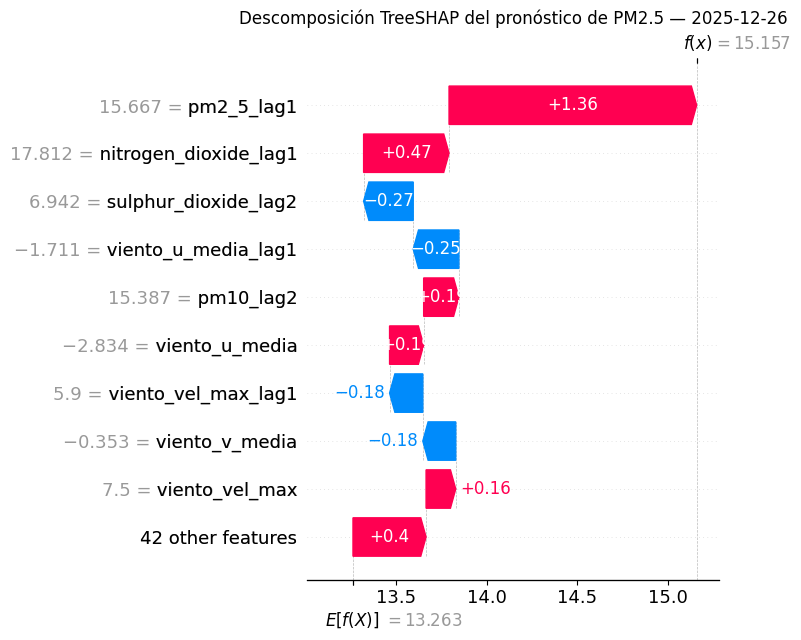

 TreeSHAP — PM10 — C. Pronóstico 24 h + meteorología (modelo seleccionado: LightGBM)


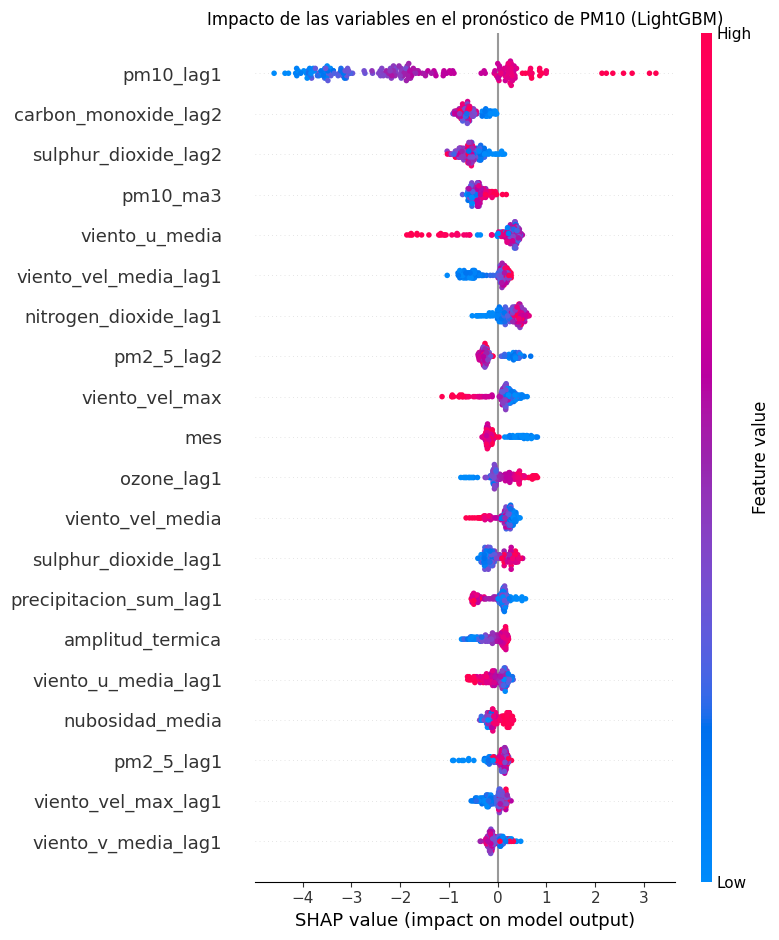

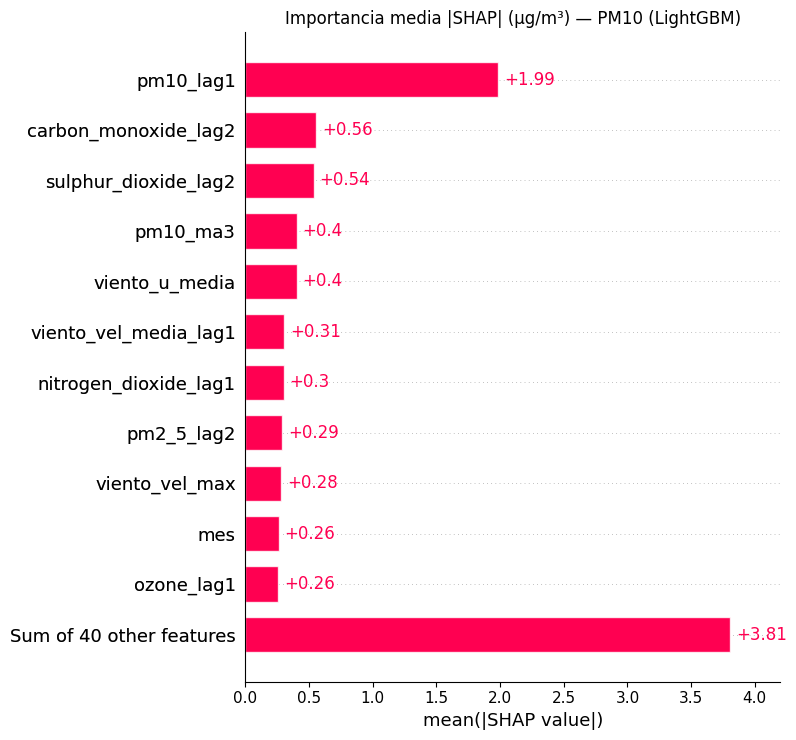

Día de mayor PM10 en prueba: 2025-08-31 (observado = 27.33 µg/m³)


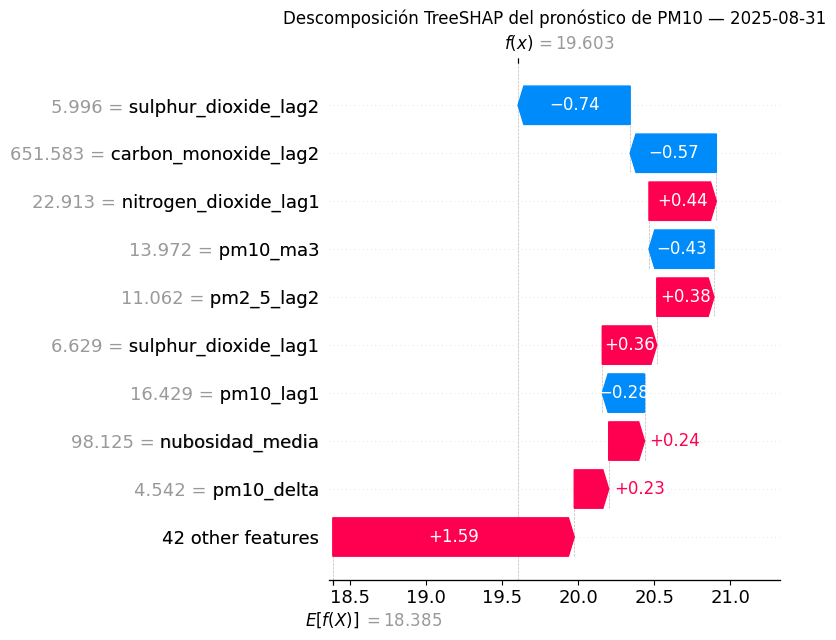

In [18]:
X_test_A = test_df[FEATURES_P]
shap_A, base_A = {}, {}
for obj, col in OBJETIVOS.items():
    mod = MEJOR[(esc_a, obj)]
    explainer = shap.TreeExplainer(modelos[(esc_a, obj, mod)])
    shap_A[obj] = explainer(X_test_A)

    print('=' * 90)
    print(f' TreeSHAP — {obj} — {esc_a} (modelo seleccionado: {mod})')
    print('=' * 90)
    plt.figure()
    shap.summary_plot(shap_A[obj], X_test_A, show=False)
    plt.title(f'Impacto de las variables en el pronóstico de {obj} ({mod})')
    plt.tight_layout(); plt.show()

    plt.figure()
    shap.plots.bar(shap_A[obj], max_display=12, show=False)
    plt.title(f'Importancia media |SHAP| (µg/m³) — {obj} ({mod})')
    plt.tight_layout(); plt.show()

    idx = int(np.argmax(test_df[col].values))
    fecha = test_df['date'].iloc[idx].strftime('%Y-%m-%d')
    print(f'Día de mayor {obj} en prueba: {fecha} (observado = {test_df[col].iloc[idx]:.2f} µg/m³)')
    plt.figure()
    shap.plots.waterfall(shap_A[obj][idx], max_display=10, show=False)
    plt.title(f'Descomposición TreeSHAP del pronóstico de {obj} — {fecha}')
    plt.tight_layout(); plt.show()

Observado: 18.57 µg/m³


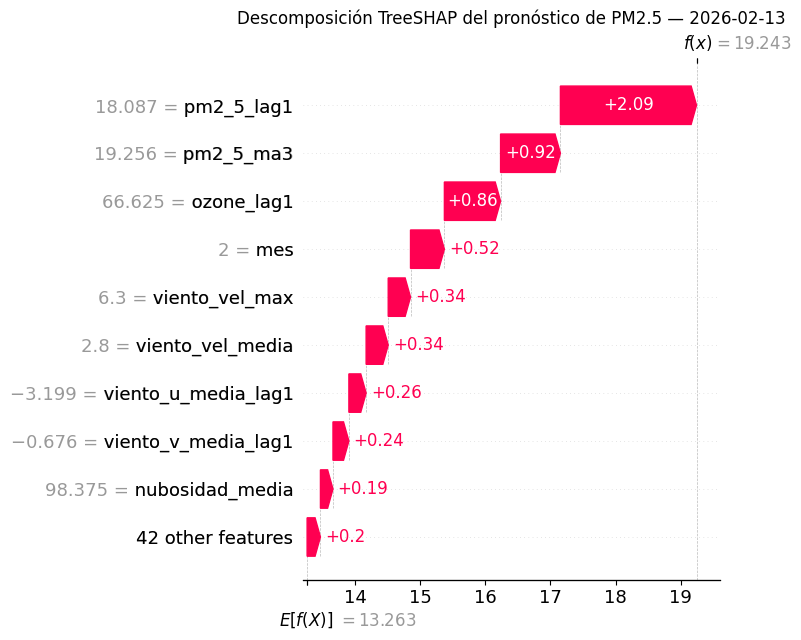

In [25]:
# Cascada de un día crítico que el modelo sí anticipó: PM2.5, 13 de febrero de 2026
idx = int(np.where(test_df['date'].dt.strftime('%Y-%m-%d') == '2026-02-13')[0][0])
print(f"Observado: {test_df['pm2_5'].iloc[idx]:.2f} µg/m³")
plt.figure()
shap.plots.waterfall(shap_A['PM2.5'][idx], max_display=10, show=False)
plt.title('Descomposición TreeSHAP del pronóstico de PM2.5 — 2026-02-13')
plt.tight_layout(); plt.show()

10.1. Comprobación de la propiedad aditiva y reconstrucción del día crítico

In [26]:
for obj, col in OBJETIVOS.items():
    mod = MEJOR[(esc_a, obj)]
    idx = int(np.argmax(test_df[col].values))
    exp = shap_A[obj][idx]
    base = float(np.ravel(exp.base_values)[0])
    suma = float(exp.values.sum())
    pred = float(modelos[(esc_a, obj, mod)].predict(X_test_A.iloc[[idx]])[0])
    real = float(test_df[col].iloc[idx])
    print('=' * 80)
    print(f" {obj} — {test_df['date'].iloc[idx].date()} ({mod})")
    print(f"  Valor base E[f(x)]            : {base:8.3f} µg/m³")
    print(f"  Suma de aportes SHAP (Σφi)    : {suma:+8.3f} µg/m³")
    print(f"  Base + Σφi                    : {base + suma:8.3f} µg/m³")
    print(f"  Predicción directa del modelo : {pred:8.3f} µg/m³")
    print(f"  Valor observado               : {real:8.3f} µg/m³  (error = {pred - real:+.3f})")
    print(f"  ¿Se cumple la propiedad aditiva? {np.isclose(base + suma, pred, atol=1e-3)}")

    detalle = pd.DataFrame({
        'Variable': FEATURES_P,
        'Valor del día': X_test_A.iloc[idx].values,
        'Media entrenamiento': train_df[FEATURES_P].mean().values,
        'Aporte SHAP (µg/m³)': exp.values,
    })
    detalle['Dirección'] = np.where(detalle['Aporte SHAP (µg/m³)'] > 0, 'Sube (+)', 'Baja (−)')
    detalle = detalle.reindex(detalle['Aporte SHAP (µg/m³)'].abs().sort_values(ascending=False).index)
    display(detalle.head(10).reset_index(drop=True))

 PM2.5 — 2025-12-26 (LightGBM)
  Valor base E[f(x)]            :   13.263 µg/m³
  Suma de aportes SHAP (Σφi)    :   +1.894 µg/m³
  Base + Σφi                    :   15.157 µg/m³
  Predicción directa del modelo :   15.157 µg/m³
  Valor observado               :   25.654 µg/m³  (error = -10.497)
  ¿Se cumple la propiedad aditiva? True


,Variable,Valor del día,Media entrenamiento,Aporte SHAP (µg/m³),Dirección
0,pm2_5_lag1,15.666667,13.259276,1.364728,Sube (+)
1,nitrogen_dioxide_lag1,17.812500,13.402973,0.470805,Sube (+)
2,sulphur_dioxide_lag2,6.941667,3.763215,-0.273419,Baja (−)
3,viento_u_media_lag1,-1.710814,-2.820991,-0.251688,Baja (−)
4,pm10_lag2,15.387500,18.405430,0.194158,Sube (+)
5,viento_u_media,-2.834302,-2.824547,0.187901,Sube (+)
6,viento_vel_max_lag1,5.900000,8.717660,-0.183201,Baja (−)
7,viento_v_media,-0.352627,-0.065786,-0.181525,Baja (−)
8,viento_vel_max,7.500000,8.723289,0.163525,Sube (+)
9,amplitud_termica,11.200000,10.304636,0.145480,Sube (+)


 PM10 — 2025-08-31 (LightGBM)
  Valor base E[f(x)]            :   18.385 µg/m³
  Suma de aportes SHAP (Σφi)    :   +1.219 µg/m³
  Base + Σφi                    :   19.603 µg/m³
  Predicción directa del modelo :   19.603 µg/m³
  Valor observado               :   27.333 µg/m³  (error = -7.730)
  ¿Se cumple la propiedad aditiva? True


,Variable,Valor del día,Media entrenamiento,Aporte SHAP (µg/m³),Dirección
0,sulphur_dioxide_lag2,5.995833,3.763215,-0.737362,Baja (−)
1,carbon_monoxide_lag2,651.583333,386.835421,-0.566855,Baja (−)
2,nitrogen_dioxide_lag1,22.912500,13.402973,0.443176,Sube (+)
3,pm10_ma3,13.972222,18.402402,-0.427808,Baja (−)
4,pm2_5_lag2,11.062500,13.260485,0.376479,Sube (+)
5,sulphur_dioxide_lag1,6.629167,3.765489,0.358449,Sube (+)
6,pm10_lag1,16.429167,18.397549,-0.278149,Baja (−)
7,nubosidad_media,98.125000,91.950423,0.235750,Sube (+)
8,pm10_delta,4.541667,-0.007882,0.226727,Sube (+)
9,viento_u_media,-1.099999,-2.824547,0.220314,Sube (+)


In [27]:
for obj in OBJETIVOS:
    sv = shap_A[obj].values
    imp = pd.Series(np.abs(sv).mean(axis=0), index=FEATURES_P)
    corr = pd.Series([np.corrcoef(X_test_A[c], sv[:, i])[0, 1] for i, c in enumerate(FEATURES_P)], index=FEATURES_P)
    tabla = pd.DataFrame({'|SHAP| medio (µg/m³)': imp.round(3),
                          'Peso (%)': (imp / imp.sum() * 100).round(1),
                          'Correlación valor–SHAP': corr.round(2)}).sort_values('|SHAP| medio (µg/m³)', ascending=False)
    print(f'--- Importancia SHAP global — {obj} ({esc_a}) ---')
    display(tabla.head(12))

--- Importancia SHAP global — PM2.5 (C. Pronóstico 24 h + meteorología) ---


,|SHAP| medio (µg/m³),Peso (%),Correlación valor–SHAP
pm2_5_lag1,1.322,18.6,0.97
nitrogen_dioxide_lag1,0.371,5.2,0.86
ozone_lag1,0.363,5.1,0.94
pm2_5_ma3,0.317,4.4,0.94
sulphur_dioxide_lag2,0.315,4.4,-0.59
viento_vel_max,0.282,4.0,-0.90
viento_u_media,0.258,3.6,-0.60
viento_vel_media,0.252,3.5,-0.95
viento_u_media_lag1,0.241,3.4,-0.79
mes,0.225,3.2,-0.81


--- Importancia SHAP global — PM10 (C. Pronóstico 24 h + meteorología) ---


,|SHAP| medio (µg/m³),Peso (%),Correlación valor–SHAP
pm10_lag1,1.986,21.2,0.95
carbon_monoxide_lag2,0.556,5.9,-0.64
sulphur_dioxide_lag2,0.535,5.7,-0.61
pm10_ma3,0.403,4.3,0.82
viento_u_media,0.403,4.3,-0.60
viento_vel_media_lag1,0.306,3.3,0.76
nitrogen_dioxide_lag1,0.300,3.2,0.83
pm2_5_lag2,0.290,3.1,-0.73
viento_vel_max,0.281,3.0,-0.91
mes,0.260,2.8,-0.89


10.2. Relación entre el valor de cada variable y su efecto (curvas de dependencia)

Se grafican las 4 variables más importantes de cada contaminante (tomadas automáticamente del ranking SHAP). El color indica el valor de la variable: azul = bajo, rojo = alto.

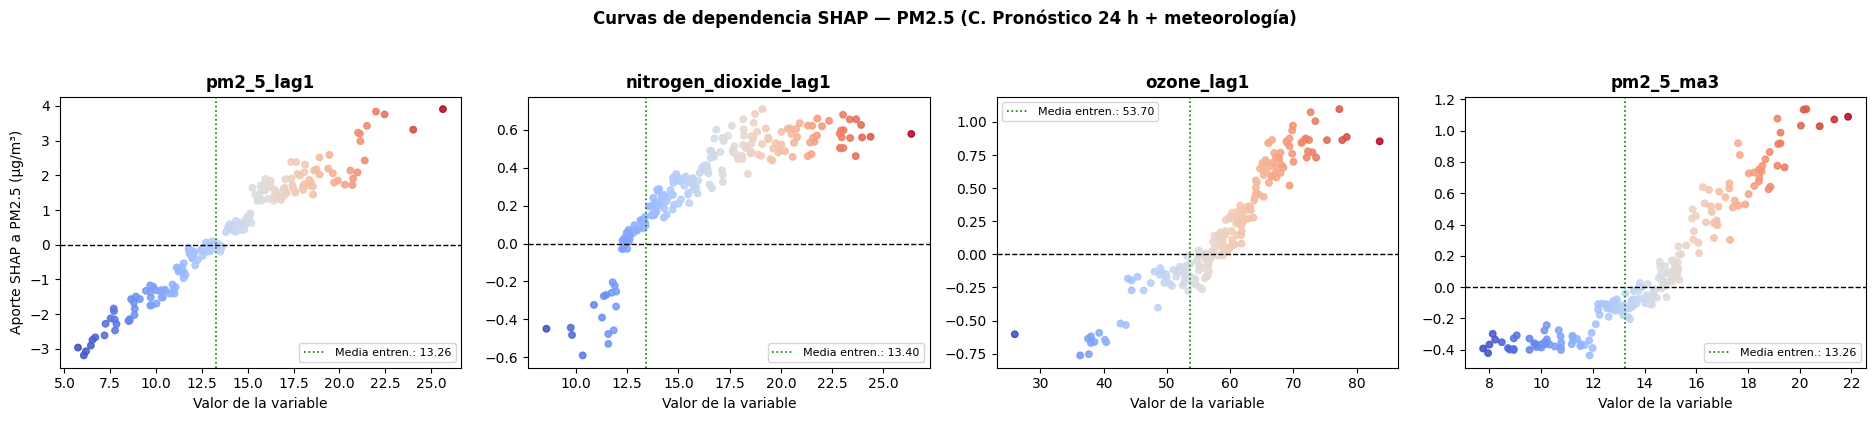

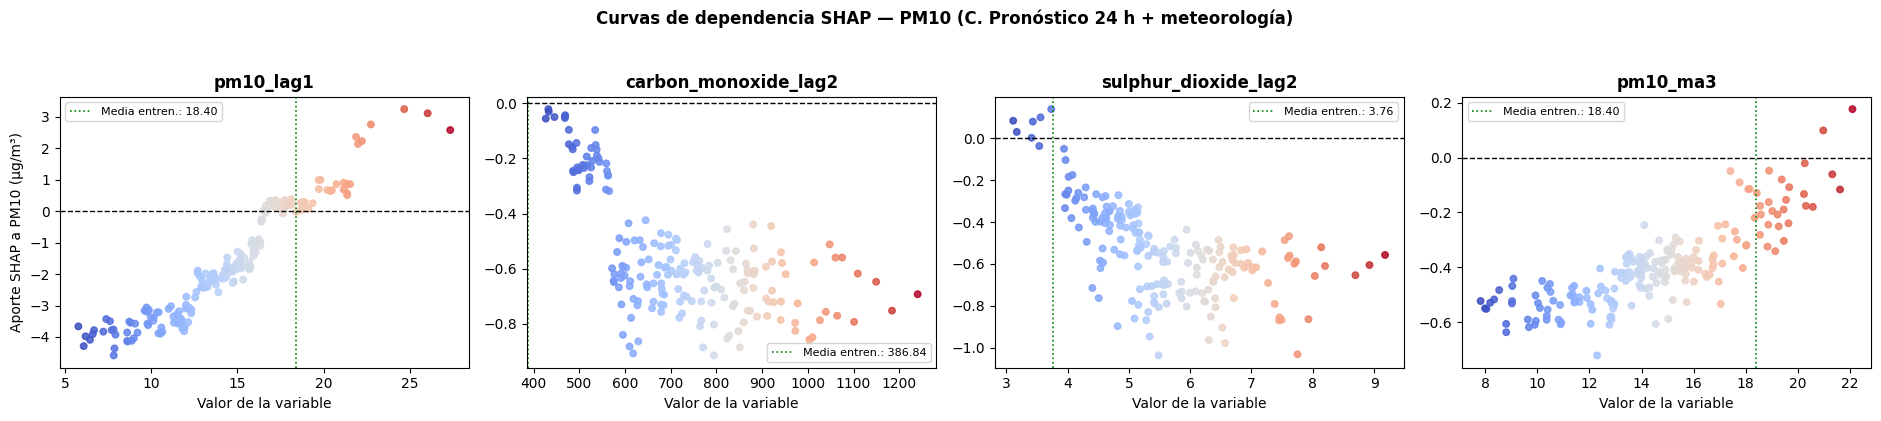

In [28]:
for obj in OBJETIVOS:
    imp = pd.Series(np.abs(shap_A[obj].values).mean(axis=0), index=FEATURES_P).sort_values(ascending=False)
    top4 = imp.index[:4].tolist()
    fig, axes = plt.subplots(1, 4, figsize=(19, 4))
    for ax, var in zip(axes, top4):
        j = FEATURES_P.index(var)
        x = X_test_A[var].values
        ax.scatter(x, shap_A[obj].values[:, j], c=x, cmap='coolwarm', s=22, alpha=0.85)
        ax.axhline(0, color='black', linestyle='--', linewidth=1)
        ax.axvline(train_df[var].mean(), color='green', linestyle=':', linewidth=1.2,
                   label=f'Media entren.: {train_df[var].mean():.2f}')
        ax.set_title(var, fontweight='bold'); ax.set_xlabel('Valor de la variable')
        ax.legend(fontsize=8)
    axes[0].set_ylabel(f'Aporte SHAP a {obj} (µg/m³)')
    plt.suptitle(f'Curvas de dependencia SHAP — {obj} ({esc_a})', fontweight='bold', y=1.04)
    plt.tight_layout(); plt.show()

10.3. Importancia por grupo de variables y comparación entre escenarios

Se agrupan los aportes SHAP por su naturaleza física. Comparar los dos escenarios muestra qué parte del poder predictivo depende de conocer el día en curso (escenario B) y cuál proviene de la memoria atmosférica y la estacionalidad (escenario A).

In [22]:
def grupo_variable(v):
    base = v[:-5] if v.endswith('_lag1') else v
    if base in COLS_METEO:
        return 'Meteorología (día previo)' if v.endswith('_lag1') else 'Meteorología (día pronosticado)'
    if v in ('mes', 'dia_semana'):
        return 'Calendario (estacionalidad)'
    if v.startswith(('pm10', 'pm2_5')):
        return 'Persistencia del material particulado (días previos)'
    if v.endswith(('_lag1', '_lag2')) and v.split('_lag')[0] in OPTICAS:
        return 'Aerosoles y radiación (día previo)'
    if v.endswith(('_lag1', '_lag2')):
        return 'Gases precursores y ozono secundario (días previos)'
    if v in OPTICAS:
        return 'Aerosoles y radiación (mismo día)'
    return 'Gases precursores y ozono secundario (mismo día)'

filas, importancias_C = [], {}
for esc, feats in ESCENARIOS.items():
    for obj in OBJETIVOS:
        modelo = modelos[(esc, obj, MEJOR[(esc, obj)])]
        sv = shap.TreeExplainer(modelo)(test_df[feats])
        imp = pd.Series(np.abs(sv.values).mean(axis=0), index=feats)
        if esc.startswith('C'):
            importancias_C[obj] = imp
        for g, v in imp.groupby(imp.index.map(grupo_variable)).sum().items():
            filas.append({'Contaminante': obj, 'Escenario': esc, 'Grupo': g,
                          'Peso relativo (%)': v / imp.sum() * 100})

tabla_grupos = pd.DataFrame(filas)
print('--- PESO RELATIVO (%) DE CADA GRUPO DE VARIABLES, POR ESCENARIO ---')
display(tabla_grupos.pivot_table(index='Grupo', columns=['Contaminante', 'Escenario'],
                                 values='Peso relativo (%)').round(1).fillna('—'))

for obj, imp in importancias_C.items():
    print(f'\n--- 12 variables más importantes — {obj} (escenario C) ---')
    display((imp / imp.sum() * 100).sort_values(ascending=False).head(12).round(1).to_frame('Peso (%)'))

--- PESO RELATIVO (%) DE CADA GRUPO DE VARIABLES, POR ESCENARIO ---


Contaminante                                                     PM10  \
Escenario                                          A. Pronóstico 24 h   
Grupo                                                                   
Aerosoles y radiación (día previo)                                4.2   
Aerosoles y radiación (mismo día)                                   —   
Calendario (estacionalidad)                                       5.6   
Gases precursores y ozono secundario (días prev...               38.3   
Gases precursores y ozono secundario (mismo día)                    —   
Meteorología (día previo)                                           —   
Meteorología (día pronosticado)                                     —   
Persistencia del material particulado (días pre...               51.9   

Contaminante                                                                \
Escenario                                          B. Estimación mismo día   
Grupo                                                                        
Aerosoles y radiación (día previo)                                       —   
Aerosoles y radiación (mismo día)                                     24.8   
Calendario (estacionalidad)                                              —   
Gases precursores y ozono secundario (días prev...                    27.8   
Gases precursores y ozono secundario (mismo día)                      26.4   
Meteorología (día previo)                                                —   
Meteorología (día pronosticado)                                          —   
Persistencia del material particulado (días pre...                    21.0   

Contaminante                                                                          \
Escenario                                          C. Pronóstico 24 h + meteorología   
Grupo                                                                                  
Aerosoles y radiación (día previo)                                               2.4   
Aerosoles y radiación (mismo día)                                                  —   
Calendario (estacionalidad)                                                      3.0   
Gases precursores y ozono secundario (días prev...                              22.2   
Gases precursores y ozono secundario (mismo día)                                   —   
Meteorología (día previo)                                                       17.7   
Meteorología (día pronosticado)                                                 21.4   
Persistencia del material particulado (días pre...                              33.3   

Contaminante                                                    PM2.5  \
Escenario                                          A. Pronóstico 24 h   
Grupo                                                                   
Aerosoles y radiación (día previo)                                7.0   
Aerosoles y radiación (mismo día)                                   —   
Calendario (estacionalidad)                                       8.8   
Gases precursores y ozono secundario (días prev...               36.4   
Gases precursores y ozono secundario (mismo día)                    —   
Meteorología (día previo)                                           —   
Meteorología (día pronosticado)                                     —   
Persistencia del material particulado (días pre...               47.9   

Contaminante                                                                \
Escenario                                          B. Estimación mismo día   
Grupo                                                                        
Aerosoles y radiación (día previo)                                       —   
Aerosoles y radiación (mismo día)                                     21.7   
Calendario (estacionalidad)                                              —   
Gases precursores y ozono secundario (días prev...                    16.5   
Gases precursores 


--- 12 variables más importantes — PM2.5 (escenario C) ---


,Peso (%)
pm2_5_lag1,18.6
nitrogen_dioxide_lag1,5.2
ozone_lag1,5.1
pm2_5_ma3,4.4
sulphur_dioxide_lag2,4.4
viento_vel_max,4.0
viento_u_media,3.6
viento_vel_media,3.5
viento_u_media_lag1,3.4
mes,3.2



--- 12 variables más importantes — PM10 (escenario C) ---


,Peso (%)
pm10_lag1,21.2
carbon_monoxide_lag2,5.9
sulphur_dioxide_lag2,5.7
pm10_ma3,4.3
viento_u_media,4.3
viento_vel_media_lag1,3.3
nitrogen_dioxide_lag1,3.2
pm2_5_lag2,3.1
viento_vel_max,3.0
mes,2.8


10.4. Curvas de dependencia de las variables meteorológicas


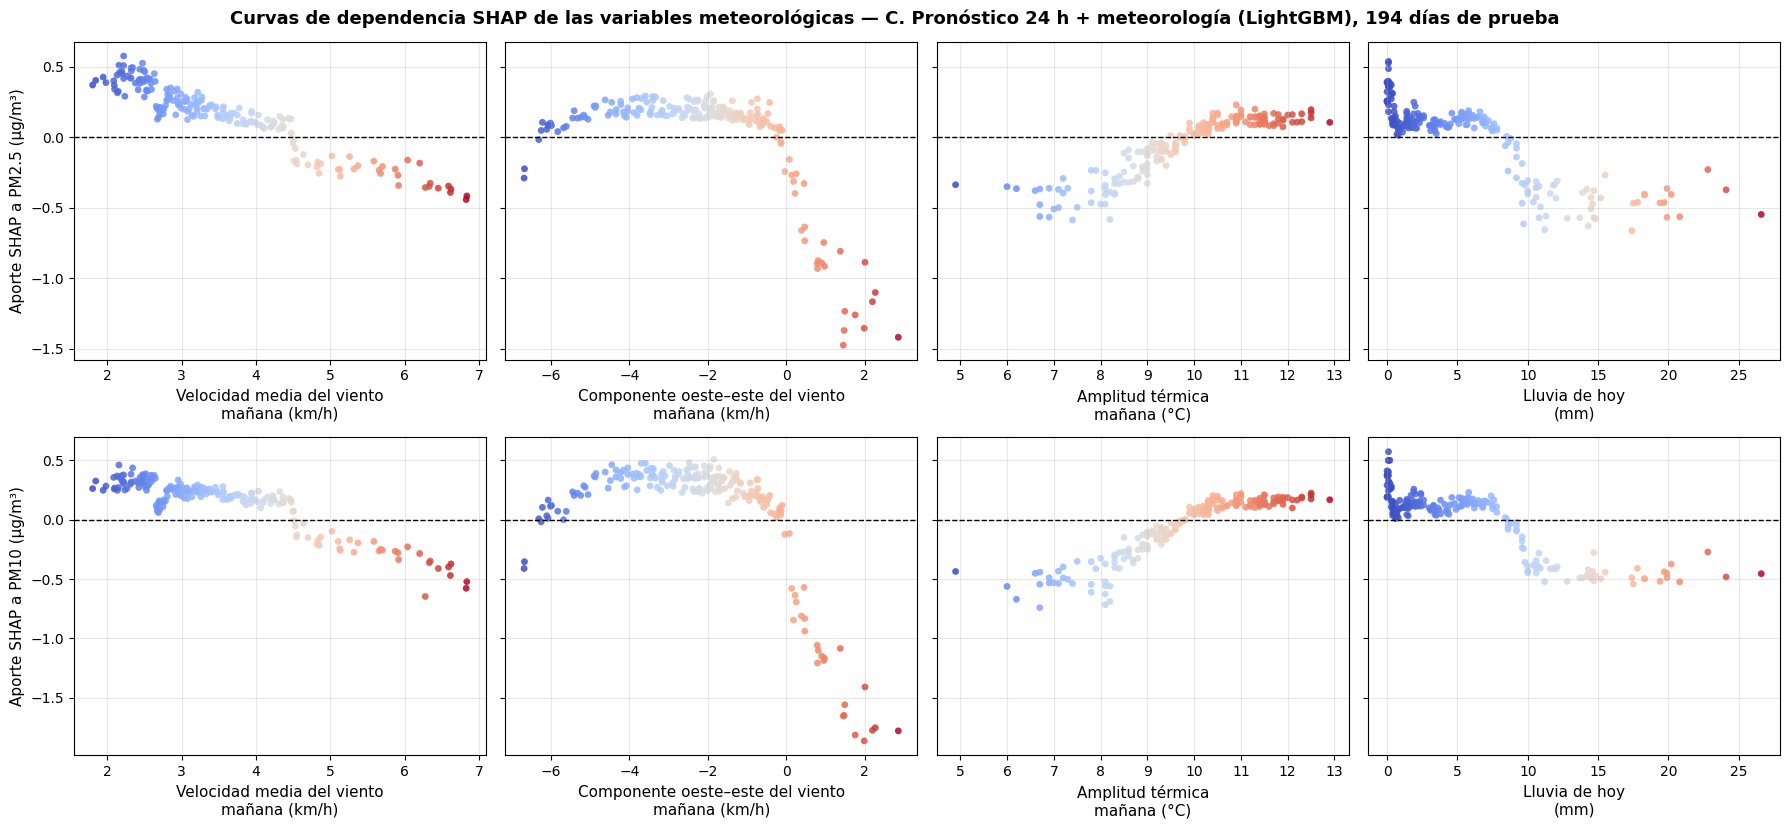

--- APORTE SHAP PROMEDIO (µg/m³) SEGÚN EL CUARTIL DEL VALOR DE LA VARIABLE ---


,Contaminante,Variable,Q1 (bajo),Q2,Q3,Q4 (alto)
0,PM2.5,viento_vel_media,0.41,0.24,0.16,-0.15
1,PM2.5,viento_u_media,0.15,0.20,0.17,-0.38
2,PM2.5,amplitud_termica,-0.34,-0.07,0.09,0.13
3,PM2.5,precipitacion_sum_lag1,0.21,0.11,0.05,-0.45
4,PM10,viento_vel_media,0.32,0.22,0.20,-0.14
5,PM10,viento_u_media,0.25,0.35,0.30,-0.53
6,PM10,amplitud_termica,-0.42,-0.08,0.11,0.16
7,PM10,precipitacion_sum_lag1,0.19,0.12,0.09,-0.43


In [23]:
# 10.4 Curvas de dependencia de las principales variables meteorológicas (escenario C)
VARS_CLIMA = [('viento_vel_media',       'Velocidad media del viento\nmañana (km/h)'),
              ('viento_u_media',         'Componente oeste–este del viento\nmañana (km/h)'),
              ('amplitud_termica',       'Amplitud térmica\nmañana (°C)'),
              ('precipitacion_sum_lag1', 'Lluvia de hoy\n(mm)')]

fig, axes = plt.subplots(2, 4, figsize=(18, 8.4), sharey='row')
for fila, obj in enumerate(OBJETIVOS):
    for ax, (var, etiqueta) in zip(axes[fila], VARS_CLIMA):
        j = FEATURES_P.index(var)
        x = X_test_A[var].values
        ax.scatter(x, shap_A[obj].values[:, j], c=x, cmap='coolwarm', s=24, alpha=0.85, edgecolor='none')
        ax.axhline(0, color='black', linestyle='--', linewidth=1)
        ax.set_xlabel(etiqueta, fontsize=11)
        ax.grid(alpha=0.3)
    axes[fila][0].set_ylabel(f'Aporte SHAP a {obj} (µg/m³)', fontsize=11)
plt.suptitle(f'Curvas de dependencia SHAP de las variables meteorológicas — {esc_a} '
             f'({MEJOR[(esc_a, "PM2.5")]}), 194 días de prueba', fontweight='bold', fontsize=13)
plt.tight_layout(); plt.show()

# Resumen numérico: aporte SHAP promedio según el cuartil del valor de cada variable
filas = []
for obj in OBJETIVOS:
    for var, _ in VARS_CLIMA:
        j = FEATURES_P.index(var)
        cuartil = pd.qcut(X_test_A[var], 4, labels=['Q1 (bajo)', 'Q2', 'Q3', 'Q4 (alto)'], duplicates='drop')
        prom = pd.Series(shap_A[obj].values[:, j], index=X_test_A.index).groupby(cuartil, observed=True).mean()
        filas.append({'Contaminante': obj, 'Variable': var, **prom.round(2).to_dict()})
print('--- APORTE SHAP PROMEDIO (µg/m³) SEGÚN EL CUARTIL DEL VALOR DE LA VARIABLE ---')
display(pd.DataFrame(filas))

11. Exportación del modelo principal para la aplicación web (Django)

In [24]:
import os, json, shutil
from google.colab import files

CARPETA_MODELOS = '/content/modelos_calidad_aire'
shutil.rmtree(CARPETA_MODELOS, ignore_errors=True)
os.makedirs(CARPETA_MODELOS, exist_ok=True)

metadatos = {'escenario': esc_a, 'variables': FEATURES_P, 'umbral_p90': UMBRAL_P90,
             'ubicacion': {'latitud': 6.2518, 'longitud': -75.5636},   # las mismas coordenadas de la descarga
             'versiones': VERSIONES, 'modelos': {}}

for obj, col in OBJETIVOS.items():
    mod = MEJOR[(esc_a, obj)]
    modelo = modelos[(esc_a, obj, mod)]
    if mod == 'LightGBM':
        nombre_archivo = f'modelo_{col}.txt'
        modelo.booster_.save_model(os.path.join(CARPETA_MODELOS, nombre_archivo))
    elif mod == 'XGBoost':
        nombre_archivo = f'modelo_{col}.json'
        modelo.save_model(os.path.join(CARPETA_MODELOS, nombre_archivo))
    else:   # Random Forest: la aplicación no lo admite, se exporta solo como respaldo
        nombre_archivo = f'modelo_{col}_{mod.replace(" ", "_")}.joblib'
        joblib.dump(modelo, os.path.join(CARPETA_MODELOS, nombre_archivo))
    r = tabla_resultados[(tabla_resultados['Escenario'] == esc_a) & (tabla_resultados['Contaminante'] == obj) &
                         (tabla_resultados['Modelo'] == mod) & (tabla_resultados['Partición'] == 'Prueba')].iloc[0]
    metadatos['modelos'][obj] = {'algoritmo': mod, 'archivo': nombre_archivo,
                                 'MAE_prueba': round(float(r['MAE']), 4), 'RMSE_prueba': round(float(r['RMSE']), 4),
                                 'R2_prueba': round(float(r['R²']), 4)}

with open(os.path.join(CARPETA_MODELOS, 'metadatos_modelos.json'), 'w', encoding='utf-8') as f:
    json.dump(metadatos, f, ensure_ascii=False, indent=2)

# Meteorología diaria: la aplicación la necesita para construir los rezagos y el promedio del mes
meteo_d.to_csv(os.path.join(CARPETA_MODELOS, 'meteorologia_diaria.csv'), index=False)

print('Escenario exportado:', esc_a, '|', len(FEATURES_P), 'variables')
for archivo in sorted(os.listdir(CARPETA_MODELOS)):
    print('  -', archivo)

shutil.make_archive('/content/modelos_calidad_aire', 'zip', CARPETA_MODELOS)
files.download('/content/modelos_calidad_aire.zip')

Escenario exportado: C. Pronóstico 24 h + meteorología | 51 variables
  - metadatos_modelos.json
  - meteorologia_diaria.csv
  - modelo_pm10.txt
  - modelo_pm2_5.txt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>